# Debug: p_z threshold fit for honeycomb 5-rep majority at $p_{res}=10^{-4}$

The `grid_bell_ler_grid_repeat5` panel at $p_{res}=10^{-4}$ shows a fit that
doesn't sit on the visual crossing. This notebook reproduces that single fit
through **both** fitting stacks in the repo:

1. **Raw estimator** — `src/threshold_fit.py` (`locate_threshold` +
   `fit_threshold`) applied directly to the p_z axis, no guards.
2. **Grid pipeline** — `plot_grid.fit_pz_threshold` (scheme-aware saturation
   cutoff + `pz_max` window + protective-regime guard), which is what the grid
   figures use, plus `analyze_axis_threshold`'s two estimators (`fss`, which
   wraps the same `fit_pz_threshold`, and `minvar`, the plateau-relative
   min-variance crossing).

Each stage's intermediate data (surviving points, locate seed, fit window) is
shown so we can see where the bad fit comes from.

In [1]:
import pathlib, sys

import numpy as np
import pandas as pd

ROOT = pathlib.Path.cwd().parent   # notebooks/ -> repo root
for p in (str(ROOT / "src"), str(ROOT / "tools" / "_grid_scans")):
    if p not in sys.path:
        sys.path.insert(0, p)

from threshold_fit import locate_threshold, fit_threshold
import plot_grid as g            # forces the Agg backend on import...
import analyze_axis_threshold as axis

%matplotlib inline
import matplotlib.pyplot as plt  # ...so switch to inline afterwards

SCHEME = "biased_bell_v3_equivalent_majority5"
P_RES_TARGET = 1e-4
CSV = ROOT / "out/collection/grid_bell.csv"


## Load the data and select the slice

In [2]:
df = g.load_grid(str(CSV))
sub_all = df[df["noise_model"] == SCHEME]
p_values = np.sort(sub_all["p"].dropna().unique())
P_RES = float(p_values[np.argmin(np.abs(p_values - P_RES_TARGET))])
print(f"scheme = {SCHEME}")
print(f"p_res  = {P_RES:g} (nearest sampled to {P_RES_TARGET:g})")

# The slice: all distances, all p_z, at this single p_res.
sl = sub_all[np.isclose(sub_all["p"], P_RES)].copy()
sl = sl.sort_values(["expected_distance", "p_bell_z"])
distances = sorted(int(d) for d in sl["expected_distance"].dropna().unique())
print(f"distances = {distances}, p_z values = {sl['p_bell_z'].nunique()}, rows = {len(sl)}")
sl[["p", "p_bell_z", "expected_distance", "shots", "errors", "pL", "sigma"]].head()


scheme = biased_bell_v3_equivalent_majority5
p_res  = 0.0001 (nearest sampled to 0.0001)
distances = [3, 5, 7], p_z values = 25, rows = 75


,p,p_bell_z,expected_distance,shots,errors,pL,sigma
4615,0.0001,0.001000,3,1000000,605,0.000605,0.000025
2358,0.0001,0.001247,3,1000000,635,0.000635,0.000025
7408,0.0001,0.001555,3,1000000,689,0.000689,0.000026
2525,0.0001,0.001939,3,1000000,633,0.000633,0.000025
4893,0.0001,0.002418,3,1000000,650,0.000650,0.000025


## The raw curves

Per-observable LER vs p_z, one curve per distance. This is what the fit is
supposed to find the crossing of.

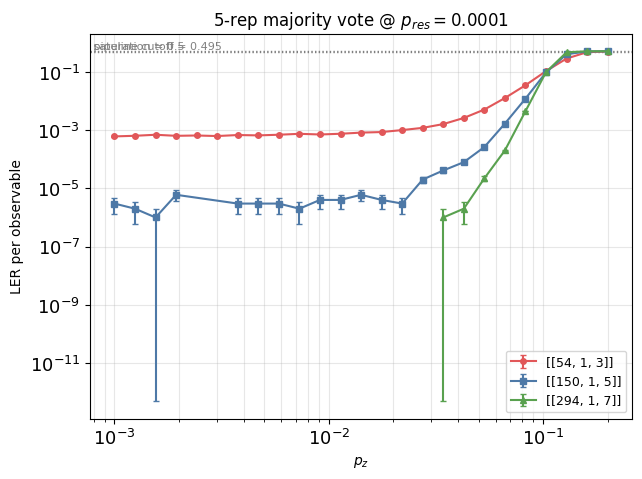

In [3]:
def plot_slice(ax, show_saturation_lines=True):
    for d in distances:
        xs, ys, es = g._pz_curve(sl, P_RES, d)
        ax.errorbar(xs, ys, yerr=es, marker=g.MARKERS.get(d, "o"),
                    color=g.COLORS.get(d), linestyle="-", markersize=4,
                    capsize=2, label=g._code_label(sl, d))
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(r"$p_z$"); ax.set_ylabel("LER per observable")
    ax.grid(True, which="both", alpha=0.3)
    if show_saturation_lines:
        for cut, lbl in [(g._pz_cutoff_for(sl), "pipeline cutoff"),
                         (0.5, "saturation")]:
            ax.axhline(cut, color="gray", linestyle=":", linewidth=1)
            ax.text(ax.get_xlim()[0], cut, f" {lbl} = {cut}", fontsize=8,
                    va="bottom", color="gray")

fig, ax = plt.subplots(figsize=(7, 5))
plot_slice(ax)
ax.legend(fontsize=9)
ax.set_title(rf"{g.scheme_label(SCHEME)} @ $p_{{res}}={P_RES:g}$")
plt.show()


## Method 1: raw `threshold_fit` on the p_z axis (no guards)

Exactly `locate_threshold` -> `fit_threshold`, fed every valid point
(errors > 0), with no saturation cutoff and no p_z window cap. This is the
estimator both pipelines share, stripped of the wrappers.

In [4]:
raw = sl[(sl["errors"] > 0) & (sl["shots"] > 0)]
pz_r = raw["p_bell_z"].to_numpy(float)
d_r = raw["expected_distance"].to_numpy(float)
pL_r = raw["pL"].to_numpy(float)
sg_r = raw["sigma"].to_numpy(float)

seed_raw = locate_threshold(pz_r, d_r, pL_r)
print(f"locate_threshold seed (no cutoff): p_z = {seed_raw:g}")

fit_raw = fit_threshold(pz_r, d_r, pL_r, sigma=sg_r, p_init=seed_raw, n_per_side=2)
print(f"fit_threshold: p_th = {fit_raw.p_th:.4g} +/- {fit_raw.p_th_err:.2g}, "
      f"mu = {fit_raw.mu:.3g} +/- {fit_raw.mu_err:.2g}, "
      f"n_points = {fit_raw.n_points}")
print(f"fit window (p_z values): {[f'{w:.4g}' for w in fit_raw.p_window]}")


locate_threshold seed (no cutoff): p_z = 0.2
fit_threshold: p_th = 0.1 +/- 0.0033, mu = 0.837 +/- 0.065, n_points = 9
fit window (p_z values): ['0.1286', '0.1604', '0.2']


## Method 2: the grid-pipeline fit (`plot_grid.fit_pz_threshold`)

What the grid figures actually draw. For this scheme (`majority5`, honeycomb
k=1) the wrapper applies:
- saturation cutoff `pL < 0.495` (`_pz_cutoff_for`),
- window cap `p_z <= 0.25` (`_pz_max_for`),
- the protective-regime guard,
- rejects fits landing outside the surviving p_z range.

We re-run its internals step by step to see which points survive and where the
locate seeds.

In [ ]:
# pz_max = g._pz_max_for(sl)
pz_max = 0.2
# cutoff = g._pz_cutoff_for(sl)
cutoff = 0.4
print(f"pipeline knobs: logical_cutoff = {cutoff}, pz_max = {pz_max}")
print(f"protective regime at p_res={P_RES:g}: {g._has_protective_regime(sl, P_RES)}")

surv = sl[(sl["errors"] > 0) & (sl["shots"] > 0)
          & (sl["p_bell_z"] <= pz_max) & (sl["pL"] < cutoff)]
dropped = sl[~sl.index.isin(surv.index) & (sl["errors"] > 0)]
print(f"points surviving cutoff+pz_max: {len(surv)} / {len(sl)} "
      f"(dropped {len(dropped)})")
print("dropped (p_z, d, pL):")
for _, r in dropped.sort_values(["expected_distance", "p_bell_z"]).iterrows():
    print(f"  p_z={r['p_bell_z']:.4g}  d={int(r['expected_distance'])}  pL={r['pL']:.3g}")

seed_pipe = locate_threshold(surv["p_bell_z"].to_numpy(float),
                             surv["expected_distance"].to_numpy(float),
                             surv["pL"].to_numpy(float))
print(f"\nlocate_threshold seed (after cutoff): p_z = {seed_pipe:g}")

fit_pipe = g.fit_pz_threshold(sl, P_RES)
if fit_pipe is None:
    print("fit_pz_threshold -> None (guard rejected it)")
else:
    print(f"fit_pz_threshold: p_th = {fit_pipe.p_th:.4g} +/- {fit_pipe.p_th_err:.2g}, "
          f"mu = {fit_pipe.mu:.3g} +/- {fit_pipe.mu_err:.2g}, "
          f"n_points = {fit_pipe.n_points}")
    print(f"fit window (p_z values): {[f'{w:.4g}' for w in fit_pipe.p_window]}")


pipeline knobs: logical_cutoff = 0.495, pz_max = 0.25
protective regime at p_res=0.0001: True
points surviving cutoff+pz_max: 53 / 75 (dropped 4)
dropped (p_z, d, pL):
  p_z=0.1604  d=5  pL=0.497
  p_z=0.2  d=5  pL=0.505
  p_z=0.1604  d=7  pL=0.504
  p_z=0.2  d=7  pL=0.505

locate_threshold seed (after cutoff): p_z = 0.103134
fit_pz_threshold: p_th = 0.1778 +/- 0.0042, mu = 0.239 +/- 0.0099, n_points = 13
fit window (p_z values): ['0.06632', '0.0827', '0.1031', '0.1286', '0.1604']


## Method 2b: `analyze_axis_threshold` estimators

`_fit(..., method='fss')` wraps the same `fit_pz_threshold` (with its own
`pz_max=0.25` for majority5), and `method='minvar'` is the plateau-relative
min-variance crossing — a fit-free reference point.

In [6]:
res_fss = axis._fit(sl, "p_bell_z", SCHEME, method="fss")
res_minvar = axis._fit(sl, "p_bell_z", SCHEME, method="minvar")
print(f"axis fss   : {res_fss[0]:.4g} +/- {res_fss[1]:.2g}" if res_fss else "axis fss   : None")
print(f"axis minvar: {res_minvar[0]:.4g} (no error bar)" if res_minvar else "axis minvar: None")


axis fss   : 0.1778 +/- 0.0042
axis minvar: 0.1031 (no error bar)


## Where does the crossing look like it is?

Variance of log(pL) across distances at each p_z — the quantity
`locate_threshold` minimizes — together with the mean rate. The minvar
estimator only trusts the minimum among points below half the plateau.

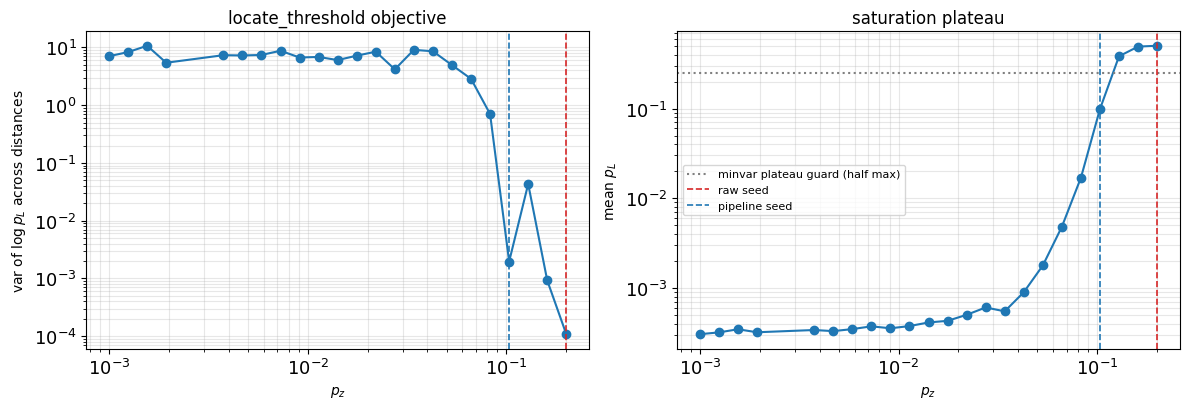

In [7]:
rows = []
for pz_val, grp in sl[(sl["errors"] > 0)].groupby("p_bell_z"):
    pl = grp["pL"].to_numpy(float)
    pl = pl[pl > 0]
    if len(pl) < 2:
        continue
    rows.append((float(pz_val), float(pl.mean()), float(np.var(np.log(pl)))))
var_df = pd.DataFrame(rows, columns=["p_z", "mean_pL", "var_log_pL"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))
ax1.plot(var_df["p_z"], var_df["var_log_pL"], "o-")
ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_xlabel(r"$p_z$"); ax1.set_ylabel(r"var of $\log p_L$ across distances")
ax1.set_title("locate_threshold objective")
ax2.plot(var_df["p_z"], var_df["mean_pL"], "o-")
ax2.axhline(0.5 * var_df["mean_pL"].max(), color="gray", linestyle=":",
            label="minvar plateau guard (half max)")
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel(r"$p_z$"); ax2.set_ylabel(r"mean $p_L$")
ax2.set_title("saturation plateau")
for ax in (ax1, ax2):
    ax.grid(True, which="both", alpha=0.3)
    for val, c, lbl in [(seed_raw, "tab:red", "raw seed"),
                        (seed_pipe, "tab:blue", "pipeline seed")]:
        if val is not None:
            ax.axvline(val, color=c, linestyle="--", linewidth=1.2, label=lbl)
ax2.legend(fontsize=8)
plt.tight_layout(); plt.show()


## Overlay: every estimate on the data, with the FSS model curves

Solid curves = data. Dotted curves = each fit's quadratic FSS model
`pL = A + B x + C x^2, x = (p_z - p_th) d^mu`, drawn over its own fit window
(shaded). Vertical lines = the four threshold estimates.

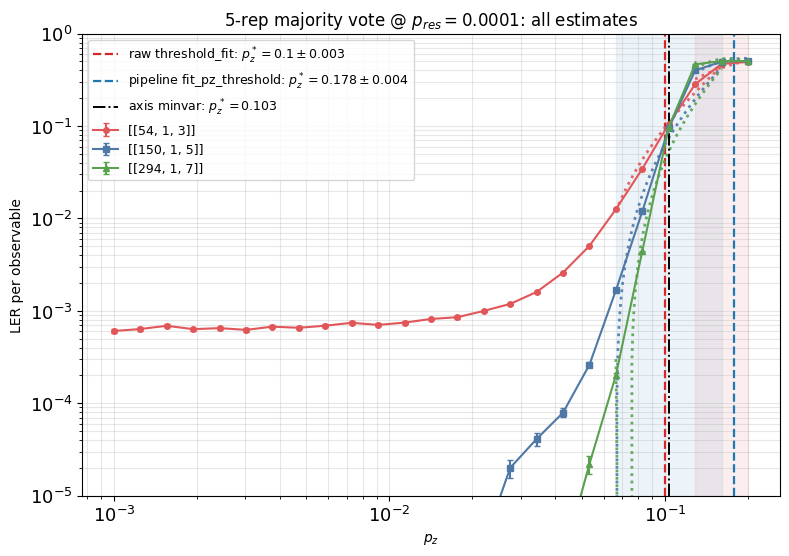

In [8]:
fig, ax = plt.subplots(figsize=(9, 6))
plot_slice(ax, show_saturation_lines=False)

fits = [("raw threshold_fit", fit_raw, "tab:red"),
        ("pipeline fit_pz_threshold", fit_pipe, "tab:blue")]
for lbl, fit, c in fits:
    if fit is None:
        continue
    ax.axvline(fit.p_th, color=c, linestyle="--", linewidth=1.6,
               label=f"{lbl}: $p_z^*={fit.p_th:.3g}\\pm{fit.p_th_err:.1g}$")
    lo, hi = min(fit.p_window), max(fit.p_window)
    ax.axvspan(lo, hi, color=c, alpha=0.08)
    pz_line = np.geomspace(lo, hi, 100)
    for d in distances:
        ax.plot(pz_line, fit.predict(pz_line, np.full_like(pz_line, d)),
                color=g.COLORS.get(d), linestyle=":", linewidth=2, alpha=0.9)

if res_minvar is not None:
    ax.axvline(res_minvar[0], color="k", linestyle="-.", linewidth=1.4,
               label=f"axis minvar: $p_z^*={res_minvar[0]:.3g}$")
if res_fss is not None and (fit_pipe is None
                            or not np.isclose(res_fss[0], fit_pipe.p_th)):
    ax.axvline(res_fss[0], color="tab:green", linestyle="--", linewidth=1.4,
               label=f"axis fss: $p_z^*={res_fss[0]:.3g}$")

ax.set_ylim(1e-5, 1.0)
ax.legend(fontsize=9, loc="upper left")
ax.set_title(rf"{g.scheme_label(SCHEME)} @ $p_{{res}}={P_RES:g}$: all estimates")
plt.show()


## FSS collapse check

If the fit is good, plotting pL against the scaling variable
$x = (p_z - p_{th})\,d^\mu$ should collapse the distances onto one curve
inside the window. A bad fit shows as distances fanning apart.

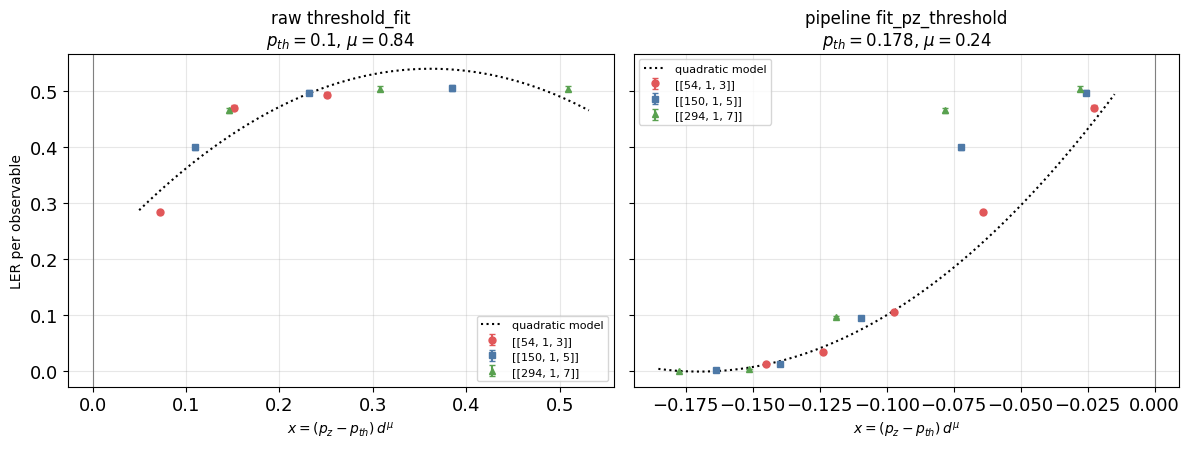

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
for ax, (lbl, fit, c) in zip(axes, fits):
    if fit is None:
        ax.set_title(f"{lbl}: no fit"); ax.axis("off"); continue
    lo, hi = min(fit.p_window), max(fit.p_window)
    w = sl[(sl["errors"] > 0) & sl["p_bell_z"].apply(
        lambda v: any(np.isclose(v, list(fit.p_window))))]
    for d in distances:
        wd = w[w["expected_distance"] == d]
        x = (wd["p_bell_z"] - fit.p_th) * d ** fit.mu
        ax.errorbar(x, wd["pL"], yerr=wd["sigma"], marker=g.MARKERS.get(d, "o"),
                    color=g.COLORS.get(d), linestyle="", markersize=5, capsize=2,
                    label=g._code_label(sl, d))
    xg = np.linspace(*ax.get_xlim(), 200)
    ax.plot(xg, fit.A + fit.B * xg + fit.C * xg**2, "k:", linewidth=1.5,
            label="quadratic model")
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.set_xlabel(r"$x = (p_z - p_{th})\,d^\mu$")
    ax.set_title(f"{lbl}\n$p_{{th}}={fit.p_th:.3g}$, $\\mu={fit.mu:.2f}$")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)
axes[0].set_ylabel("LER per observable")
plt.tight_layout(); plt.show()


## Summary table

In [10]:
summary = pd.DataFrame([
    ("raw threshold_fit (no guards)", fit_raw.p_th, fit_raw.p_th_err, fit_raw.mu),
    ("pipeline fit_pz_threshold", *((fit_pipe.p_th, fit_pipe.p_th_err, fit_pipe.mu)
                                    if fit_pipe else (np.nan,)*3)),
    ("axis_threshold fss", *((res_fss[0], res_fss[1], np.nan)
                             if res_fss else (np.nan,)*3)),
    ("axis_threshold minvar", *((res_minvar[0], np.nan, np.nan)
                                if res_minvar else (np.nan,)*3)),
], columns=["method", "p_z threshold", "err", "mu"])
summary


,method,p_z threshold,err,mu
0,raw threshold_fit (no guards),0.100000,0.003320,0.836504
1,pipeline fit_pz_threshold,0.177836,0.004158,0.238748
2,axis_threshold fss,0.177836,0.004158,NaN
3,axis_threshold minvar,0.103134,NaN,NaN
